# 残差 POD–DeepONet：三维位移预测与地层反演
按 `Manuscript.docx` 的方法与结果流程整理，适用 Jupyter Notebook / JupyterLab。

执行顺序：冻结120工况 → 训练集POD空间基 → 二次跳连+Tanh残差分支 → 独立测试 → 21点沉降反演 → 噪声与COMSOL复核。

默认加载论文已训练权重并重新计算18工况预测和一个八初值反演；完整重训练通过 `RUN_TRAINING=True` 启用。新结果仅写入 `run_outputs/`，不会覆盖论文权重。

**数据口径**：位移为mm，坐标/层厚为m，应力增量为kPa；原始uz保持向上为正，反演沉降采用−uz。观测来自COMSOL数模，不是现场监测。新坐标依赖插值，不能把原生网格精度等同于任意坐标精度。


In [1]:
from pathlib import Path
import sys, json, hashlib, time, copy
import numpy as np
import pandas as pd
import torch
from scipy.optimize import minimize
from scipy.stats import qmc
import matplotlib.pyplot as plt
from IPython.display import display

BASE=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'models/最佳神经算子.pt').exists())
OUT=BASE/'run_outputs'; OUT.mkdir(exist_ok=True)
torch.set_num_threads(1)
RUN_TRAINING=False
RUN_ALL_INVERSION=False
RUN_NOISE=False
def digest(p): return hashlib.sha256(Path(p).read_bytes()).hexdigest()
print('Python:',sys.version.split()[0], 'Torch:',torch.__version__, '数据目录:',BASE)


Python: 3.10.20 Torch: 2.5.1+cpu 数据目录: E:\7.4神经算子写作版本\1.0cg投稿\代码与数模数据


## 1. 工况数据库与冻结划分（手稿3.3）
独立样本数为120，每类14训练、3验证、3测试；地表24576点、域内4820点。空间点不能跨集合随机拆分。全量压缩CSV保存在data/hf；下面的NPZ采用共享坐标以减少重复存储。


In [2]:
manifest=pd.read_csv(BASE/'tables/120工况与冻结划分.csv')
database=pd.read_csv(BASE/'tables/120工况参数与数模响应.csv')
assert manifest.case_id.nunique()==120
assert manifest.groupby('split').size().to_dict()=={'test':18,'train':84,'validation':18}
display(pd.crosstab(manifest.family,manifest.split))
archive=np.load(BASE/'data/HF_120cases.npz',allow_pickle=False)
assert np.array_equal(archive['case_ids'],manifest.case_id.to_numpy())
S=archive['surface_uz_mm']; V=archive['volume_values']
SX=archive['surface_xyz']; VX=archive['volume_xyz']
assert S.shape==(120,24576) and V.shape==(120,4820,9)
train=np.flatnonzero(manifest.split.eq('train')); valid=np.flatnonzero(manifest.split.eq('validation')); test=np.flatnonzero(manifest.split.eq('test'))
H=manifest[['h31_m','h32_m','h33_m']].to_numpy(float)
print('全量记录:',S.size+120*V.shape[1], '（空间查询记录，不作为独立工况计数）')
display(database[['case_id','family','split','h31_m','h32_m','h33_m','HF_surface_query_peak_mm','HF_native_peak_mm']].head())


split,test,train,validation
family,,,
A,3,14,3
B,3,14,3
C,3,14,3
D,3,14,3
E,3,14,3
F,3,14,3


全量记录: 3527520 （空间查询记录，不作为独立工况计数）


,case_id,family,split,h31_m,h32_m,h33_m,HF_surface_query_peak_mm,HF_native_peak_mm
0,MC001,A,train,17.000000,3.900000,3.900000,9.886341,9.896936
1,MC002,A,train,17.682682,3.543715,3.429993,9.491752,9.500827
2,MC003,A,train,17.233063,3.844891,3.329576,9.967294,9.979138
3,MC004,A,train,14.773654,4.363661,3.870704,11.403730,11.423339
4,MC005,A,test,14.484946,4.280227,3.644500,11.618339,11.629570


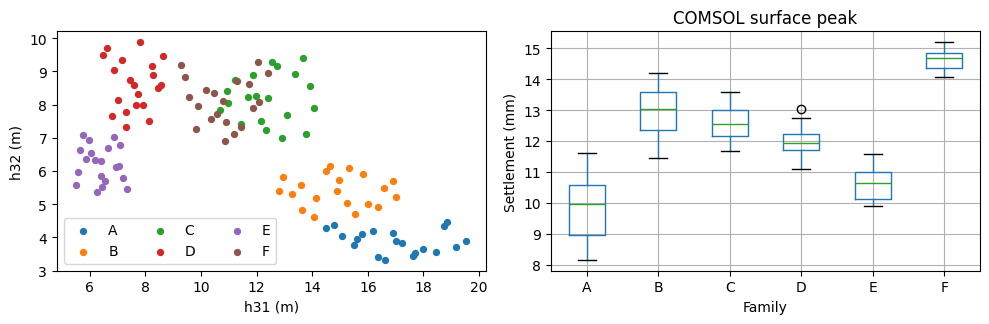

In [3]:
fig,ax=plt.subplots(1,2,figsize=(10,3.5))
for family,g in database.groupby('family'):
    ax[0].scatter(g.h31_m,g.h32_m,label=family,s=18)
ax[0].set(xlabel='h31 (m)',ylabel='h32 (m)'); ax[0].legend(ncol=3)
database.boxplot(column='HF_surface_query_peak_mm',by='family',ax=ax[1]); ax[1].set(title='COMSOL surface peak',xlabel='Family',ylabel='Settlement (mm)')
fig.suptitle(''); fig.tight_layout(); plt.show()


## 2. 训练集POD主干（手稿2.1、4.1）
去均值后的84训练快照秩最多83。各响应组采用83模态；均值、归一化和模态只由训练集确定。验证/测试需要计入投影空间外的残差。
这里提供从原始数据重建POD的函数；默认读取原权重中的空间基，保留原模型的模态符号和次序。


In [4]:
fields=[dict(np.load(BASE/f'models/POD_{n}.npz')) for n in ['surface','displacement','stress']]
meta=dict(np.load(BASE/'models/空间基与训练参数.npz')); offsets=meta['offsets'].astype(int)
assert np.array_equal(meta['train_ids'],manifest.iloc[train].case_id.to_numpy())
Y=[S,V[:,:,:3].reshape(120,-1),V[:,:,3:].reshape(120,-1)]
def rebuild_pod(y,rank=83):
    snapshots=y[train]
    mean=snapshots.mean(0)
    u,s,vt=np.linalg.svd(snapshots-mean,full_matrices=False)
    basis=vt[:rank]
    return {'mean':mean,'basis':basis,'coefficient':(snapshots-mean)@basis.T,'singular_values':s}
for name,f,y in zip(['surface','displacement','stress'],fields,Y):
    assert f['basis'].shape[0]==83
    coeff=(y[train]-f['mean'])@f['basis'].T
    np.testing.assert_allclose(coeff,f['coefficient'],rtol=1e-7,atol=1e-7)
    error=np.linalg.norm(f['mean']+coeff@f['basis']-y[train])/np.linalg.norm(y[train])
    print(name, 'basis:',f['basis'].shape, 'training reconstruction L2:',error)


surface basis: (83, 24576) training reconstruction L2: 5.053792764345734e-13
displacement basis: (83, 14460) training reconstruction L2: 4.581377984820683e-15


stress basis: (83, 28920) training reconstruction L2: 7.568316885563678e-16


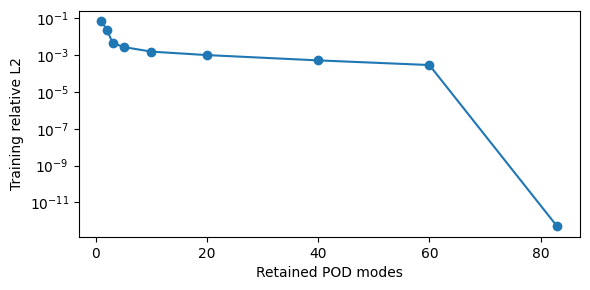

In [5]:
f=fields[0]; centered=S[train]-f['mean']; coefficients=centered@f['basis'].T
ranks=[1,2,3,5,10,20,40,60,83]
errors=[np.linalg.norm(centered-coefficients[:,:r]@f['basis'][:r])/np.linalg.norm(S[train]) for r in ranks]
plt.figure(figsize=(6,3)); plt.semilogy(ranks,errors,'o-'); plt.xlabel('Retained POD modes');plt.ylabel('Training relative L2');plt.tight_layout();plt.show()


## 3. 二次跳连与非线性残差分支（手稿2.2）
以下为实际模型类源码。输入是三层厚度；10项二次多项式与两层48宽Tanh网络共同预测系数。原实现保留三类响应，手稿重点报告地表与三分量位移。部署的地表/位移采用单成员，应力采用三成员集成，选择依据仅为验证数据。


In [6]:
# -*- coding: utf-8 -*-
"""HF-only POD-DeepONet. Trainable MLP branches; no RBF or kernel regression."""
from pathlib import Path
import itertools
import numpy as np
import torch
from torch import nn
from scipy.interpolate import RegularGridInterpolator,LinearNDInterpolator
from scipy.spatial import cKDTree

PROTOTYPES=np.array([[17,3.9,3.9],[14.9,5.4,1.6],[12.4,8.2,7.4],[7.6,8.6,9],[6.4,6.3,10.2],[10.8,8.1,2.7]],float)
def monomials(degree):return [(0,0,0)]+[a for k in range(1,degree+1) for a in itertools.product(range(k+1),repeat=3) if sum(a)==k]

class CoefficientBranch(nn.Module):
    def __init__(self,output_dim,parameter_mean,parameter_std,degree=2,conditioned=True,width=48):
        super().__init__();self.output_dim=output_dim;self.degree=degree;self.conditioned=conditioned;self.width=width
        self.register_buffer('parameter_mean',torch.tensor(parameter_mean,dtype=torch.float64));self.register_buffer('parameter_std',torch.tensor(parameter_std,dtype=torch.float64));self.register_buffer('prototypes',torch.tensor(PROTOTYPES,dtype=torch.float64))
        self.powers=monomials(degree);self.groups=6 if conditioned else 1
        self.skip=nn.Parameter(torch.zeros(self.groups,len(self.powers),output_dim,dtype=torch.float64))
        self.encoder=nn.Sequential(nn.Linear(3,width),nn.Tanh(),nn.Linear(width,width),nn.Tanh())
        self.head=nn.Parameter(torch.empty(self.groups,width,output_dim,dtype=torch.float64));nn.init.normal_(self.head,std=1e-4)
        self.double()
    def coordinates(self,h,family=None):
        if self.conditioned:
            if family is None:raise ValueError('Known borehole family A-F must be supplied; it is an explicit model input.')
            index=family.long();x=(h-self.prototypes[index])/(self.prototypes[index]*.15)
        else:index=torch.zeros(len(h),dtype=torch.long,device=h.device);x=(h-self.parameter_mean)/self.parameter_std
        return x,index
    def polynomial_features(self,x):
        return torch.stack([torch.prod(x**torch.tensor(a,device=x.device),dim=1) for a in self.powers],dim=1)
    def forward(self,h,family=None,residual=True):
        x,index=self.coordinates(h,family);features=self.polynomial_features(x);y=torch.einsum('bi,bij->bj',features,self.skip[index])
        if residual:y=y+torch.einsum('bi,bij->bj',self.encoder(x),self.head[index])
        return y

class NeuralOperator:
    def __init__(self,root=None):
        self.root=Path(root) if root else BASE/'models'
        self.ck=torch.load(self.root/'最佳神经算子.pt',map_location='cpu',weights_only=False)
        assert self.ck['architecture']=='ResidualPODDeepONet' and not self.ck['uses_RBF']
        self.meta=dict(np.load(self.root/'空间基与训练参数.npz'));self.fields=[dict(np.load(self.root/f'POD_{n}.npz')) for n in ['surface','displacement','stress']]
        self.members=[]
        for member in self.ck['members']:
            model=CoefficientBranch(**member['config']);model.load_state_dict(member['state_dict']);model.eval();self.members.append(model)
    @property
    def requires_family(self):return any(m.conditioned for m in self.members)
    def coefficients(self,h,family=None,residual=True):
        h=torch.as_tensor(h,dtype=torch.float64).reshape(-1,3)
        if family is not None:
            if isinstance(family,str):family=[family]
            family=torch.tensor([ord(v)-65 if isinstance(v,str) else int(v) for v in family],dtype=torch.long)
        outputs=torch.stack([m(h,family,residual=residual) for m in self.members])
        if 'response_member_indices' not in self.ck:return outputs.mean(0)
        off=self.meta['offsets'];return torch.cat([outputs[indices,:,off[j]:off[j+1]].mean(0) for j,indices in enumerate(self.ck['response_member_indices'])],dim=1)
    def differentiable_surface(self,h,family=None,indices=None):
        c=self.coefficients(h,family);f=self.fields[0];end=int(self.meta['offsets'][1]);basis=f['basis'] if indices is None else f['basis'][:,indices];mean=f['mean'] if indices is None else f['mean'][indices]
        return torch.as_tensor(mean)+(c[:,:end]*float(f['normalizer']))@torch.as_tensor(basis)
    def native(self,h,family=None):
        with torch.no_grad():c=self.coefficients(h,family).numpy()
        off=self.meta['offsets'];out=[f['mean']+(c[:,off[j]:off[j+1]]*float(f['normalizer']))@f['basis'] for j,f in enumerate(self.fields)]
        return out[0],np.concatenate([out[1].reshape(-1,len(self.meta['volume_xyz']),3),out[2].reshape(-1,len(self.meta['volume_xyz']),6)],axis=2)
    def query(self,h,xyz,family=None,kind='surface'):
        """New positions use explicitly documented interpolation; no extrapolation."""
        xyz=np.asarray(xyz,float).reshape(-1,3);s,v=self.native(h,family)
        if len(s)!=1:raise ValueError('Spatial query accepts one geometry at a time.')
        if kind=='surface':
            xy=self.meta['surface_xyz'];xs=np.unique(xy[:,0]);ys=np.unique(xy[:,1]);ix=np.lexsort((xy[:,0],xy[:,1]));return RegularGridInterpolator((ys,xs),s[0,ix].reshape(len(ys),len(xs)),bounds_error=True)(xyz[:,[1,0]])[:,None]
        if np.any((xyz[:,1]<0)&(xyz[:,0]**2+(xyz[:,2]+21.623)**2<8.32**2)):raise ValueError('Query in tunnel void.')
        points=self.meta['volume_xyz'];dist,ix=cKDTree(points).query(xyz);out=np.empty((len(xyz),9));exact=dist<1e-7;out[exact]=v[0,ix[exact]]
        if np.any(~exact):out[~exact]=LinearNDInterpolator(points,v[0],fill_value=np.nan)(xyz[~exact])
        if not np.isfinite(out).all():raise ValueError('Query outside native convex hull; extrapolation is disabled.')
        return out


In [7]:
op=NeuralOperator(BASE/'models')
freeze=json.loads((BASE/'results/测试前模型冻结.json').read_text('utf-8'))
assert digest(BASE/'models/最佳神经算子.pt')==freeze['checkpoint_sha256']
assert not op.requires_family
assert op.ck['response_member_indices'][0]==[0]
print('冻结模型SHA256:',freeze['checkpoint_sha256'])
display(pd.read_csv(BASE/'tables/分响应神经分支验证选择.csv'))
display(pd.read_csv(BASE/'tables/全部候选验证选择.csv').sort_values('validation_surface_relative_L2').head())


冻结模型SHA256: 422da9c1ab97f5b7af9417e61424b391d00ea6737ee9979563ea08b0b2123215


,response,candidate,validation_relative_L2,member_indices
0,surface,GlobalQuadraticResidual_seed2026103103,0.005613,[0]
1,volume,GlobalQuadraticResidual_seed2026103103,0.015326,[0]
2,stress,GlobalQuadraticResidual_ensemble3,0.170309,"[1, 2, 0]"


,candidate,conditioned,degree,ridge,ensemble_size,validation_objective,validation_surface_relative_L2,validation_volume_relative_L2,validation_stress_relative_L2
6,GlobalQuadraticResidual_seed2026103103,False,2,0.10,1,0.064711,0.005613,0.015326,0.173195
7,GlobalQuadraticResidual_ensemble3,False,2,0.10,3,0.064195,0.006092,0.016184,0.170309
18,FamilyQuadraticResidual_r01_seed2026103103,True,2,0.10,1,0.085354,0.006288,0.018778,0.230996
19,FamilyQuadraticResidual_r01_ensemble3,True,2,0.10,3,0.085386,0.006458,0.018755,0.230945
8,FamilyLinearResidual_seed2026103101,True,1,0.01,1,0.081754,0.006505,0.018064,0.220692


## 4. 可选完整重训练（手稿4.1）
默认不执行。设RUN_TRAINING=True可按原始6配置×3随机种子×2500步重训练，单线程CPU原记录约60.8分钟。权重每100步按验证集保存；先完成联合选择，再按响应选择。训练目标与原代码一致，包含应力辅助输出，因此不是仅双响应重新设计的训练。

仅使用train及validation数组；test不参与模型选择。新POD可用rebuild_pod重建，复现论文数值时采用随包原空间基。不同软件版本可造成细小数值差异。


In [8]:
def train_candidates(steps=2500, seeds=None, specs=None, output_name='retrained'):
    target_dir=OUT/output_name; target_dir.mkdir(exist_ok=True)
    protocol=json.loads((BASE/'results/训练前冻结方案.json').read_text('utf-8'))
    off=offsets
    C=np.concatenate([f['coefficient']/float(f['normalizer']) for f in fields],axis=1)
    cv=[]; perp=[]; denv=[]; dent=[]
    for f,y in zip(fields,Y):
        centered=y[valid]-f['mean']; c=centered@f['basis'].T; scale=float(f['normalizer'])
        cv.append(c/scale)
        perp.append(np.maximum(np.sum(centered**2,1)-np.sum(c**2,1),0)/scale**2)
        denv.append(np.sum(y[valid]**2,1)/scale**2)
        dent.append(np.sum(y[train]**2,1)/scale**2)
    CV=np.concatenate(cv,1); perpv=np.stack(perp,1); dv=np.stack(denv,1)
    ht=torch.tensor(H[train]); hv=torch.tensor(H[valid]); ct=torch.tensor(C); dt=torch.tensor(np.stack(dent,1))
    families=np.array([ord(f)-65 for f in manifest.family]); ft=torch.tensor(families[train]); fv=torch.tensor(families[valid])
    def metric(p):
        sq=np.stack([((p[:,off[j]:off[j+1]]-CV[:,off[j]:off[j+1]])**2).sum(1) for j in range(3)],1)
        return np.sqrt((sq+perpv)/dv).mean(0)
    candidates=[]; logs=[]
    for spec in (specs if specs is not None else protocol['candidates']):
        members=[]; predictions=[]
        for seed in (seeds if seeds is not None else protocol['seeds']):
            torch.manual_seed(seed)
            config=dict(output_dim=C.shape[1],parameter_mean=meta['parameter_mean'].tolist(),parameter_std=meta['parameter_std'].tolist(),degree=spec['degree'],conditioned=spec['conditioned'],width=48)
            model=CoefficientBranch(**config)
            with torch.no_grad():
                x,ix=model.coordinates(ht,ft); features=model.polynomial_features(x)
                for group in range(model.groups):
                    a=features[ix==group]; target=ct[ix==group]
                    penalty=torch.eye(a.shape[1],dtype=torch.float64)*spec['ridge']; penalty[0,0]=1e-9
                    model.skip[group].copy_(torch.linalg.solve(a.T@a+penalty,a.T@target))
            optimizer=torch.optim.Adam(model.parameters(),lr=.001)
            schedule=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,steps,eta_min=1e-5)
            best=np.inf; chosen=None
            for step in range(steps+1):
                pred=model(ht,ft)
                data_loss=torch.stack([((pred[:,off[j]:off[j+1]]-ct[:,off[j]:off[j+1]])**2).sum(1)/dt[:,j] for j in range(3)],1).mean()
                penalty=(model.skip[:,1:]**2).sum()/len(train)*spec['ridge']/3+(model.head**2).mean()*1e-3
                if step%100==0 or step==steps:
                    with torch.no_grad(): metrics=metric(model(hv,fv).numpy())
                    logs.append(dict(candidate=spec['name'],seed=seed,step=step,train_loss=float(data_loss.detach()),validation_objective=float(metrics.mean())))
                    if step>0 and metrics.mean()<best:
                        best=metrics.mean(); chosen=dict(config=config,state_dict=copy.deepcopy(model.state_dict()),selected_step=step,seed=seed,validation_metrics=metrics.tolist())
                if step==steps:break
                optimizer.zero_grad(); (data_loss+penalty).backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1.);optimizer.step();schedule.step()
            model.load_state_dict(chosen['state_dict']);members.append(chosen)
            with torch.no_grad():predictions.append(model(hv,fv).numpy())
            candidates.append(dict(name=f"{spec['name']}_seed{seed}",members=[chosen],metrics=metric(predictions[-1])))
        candidates.append(dict(name=spec['name']+'_ensemble3',members=members,metrics=metric(np.mean(predictions,axis=0))))
        print('trained:',spec['name'])
    members=[]; seen={}; groups=[]; selected=[]
    for j in range(3):
        winner=min(candidates,key=lambda c:c['metrics'][j]); indices=[]
        for member in winner['members']:
            weight_hash=hashlib.sha256(b''.join(v.detach().cpu().numpy().tobytes() for v in member['state_dict'].values())).hexdigest()
            key=(weight_hash,member['seed'],member['selected_step'])
            if key not in seen:seen[key]=len(members);members.append(member)
            indices.append(seen[key])
        groups.append(indices);selected.append(winner['name'])
    checkpoint=dict(architecture='ResidualPODDeepONet',uses_RBF=False,members=members,response_member_indices=groups,response_selection=selected)
    torch.save(checkpoint,target_dir/'最佳神经算子.pt')
    pd.DataFrame(logs).to_csv(target_dir/'training_log.csv',index=False)
    for name in ['空间基与训练参数.npz','POD_surface.npz','POD_displacement.npz','POD_stress.npz']:
        import shutil
        shutil.copy2(BASE/'models'/name,target_dir/name)
    return checkpoint

if RUN_TRAINING:
    new_checkpoint=train_candidates()
else:
    print('跳过重训练，采用手稿冻结权重复现。')


跳过重训练，采用手稿冻结权重复现。


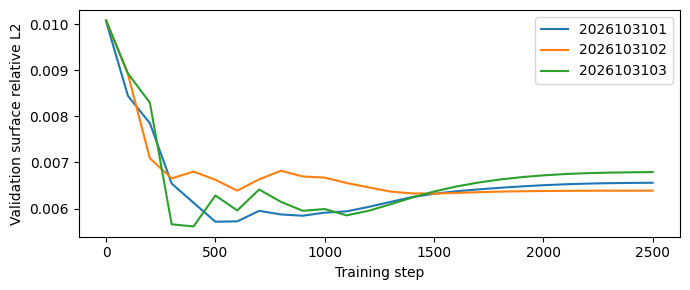

In [9]:
history=pd.read_csv(BASE/'tables/训练与验证记录.csv')
selected=history.query("candidate=='GlobalQuadraticResidual'")
fig,ax=plt.subplots(figsize=(7,3))
for seed,g in selected.groupby('seed'):ax.plot(g.step,g.validation_surface_relative_L2,label=str(seed))
ax.set(xlabel='Training step',ylabel='Validation surface relative L2');ax.legend();plt.tight_layout();plt.show()


## 5. 18个独立测试工况重新推理（手稿4.2）
在固定权重下逐工况计算，RMSE与相对L2均先按工况计算再等权平均。相对L2在CSV中用比例，不是百分数。峰值采用同一原生查询网格上min(uz)的差。


In [10]:
def field_metrics(truth,pred):
    e=pred-truth
    return dict(RMSE=float(np.sqrt(np.mean(e**2))),MAE=float(np.mean(abs(e))),MaxAE=float(abs(e).max()),relative_L2=float(np.linalg.norm(e)/np.linalg.norm(truth)),R2=float(1-np.sum(e**2)/np.sum((truth-truth.mean())**2)))
rows=[]; predictions={}
for i in test:
    cid=manifest.iloc[i].case_id
    sp,vp=op.native(H[i]);sp=sp[0];vp=vp[0]
    predictions[cid]=(sp,vp)
    row=dict(case_id=cid,family=manifest.iloc[i].family)
    for prefix,true,pred in [('surface',S[i],sp),('volume',V[i,:,:3],vp[:,:3])]:
        row.update({prefix+'_'+k:v for k,v in field_metrics(true,pred).items()})
    row['surface_peak_error_mm']=float(abs(sp.min()-S[i].min()));rows.append(row)
metrics=pd.DataFrame(rows);metrics.to_csv(OUT/'test_metrics_recomputed.csv',index=False,encoding='utf-8-sig')
recorded=pd.read_csv(BASE/'tables/18测试工况指标.csv').set_index('case_id')
for col,ref in [('surface_RMSE','surface_RMSE_mm'),('surface_relative_L2','surface_relative_L2'),('volume_RMSE','volume_RMSE_mm'),('volume_relative_L2','volume_relative_L2')]:
    np.testing.assert_allclose(metrics[col],recorded.loc[metrics.case_id,ref],rtol=2e-5,atol=1e-7)
display(metrics)
display(metrics.select_dtypes('number').mean().to_frame('18 cases mean'))


,case_id,family,surface_RMSE,surface_MAE,surface_MaxAE,surface_relative_L2,surface_R2,volume_RMSE,volume_MAE,volume_MaxAE,volume_relative_L2,volume_R2,surface_peak_error_mm
0,MC005,A,0.014576,0.008247,0.070251,0.004657,0.999972,0.070427,0.022210,1.031184,0.018171,0.999669,0.030144
1,MC009,A,0.018080,0.010709,0.070624,0.006551,0.999945,0.053002,0.018540,0.771979,0.013865,0.999807,0.057112
2,MC015,A,0.005974,0.003484,0.043325,0.002205,0.999994,0.054407,0.017630,1.089907,0.014209,0.999797,0.010812
3,MC027,B,0.018690,0.010831,0.079360,0.005776,0.999956,0.051860,0.017698,1.000556,0.013147,0.999827,0.044254
4,MC033,B,0.005483,0.003365,0.039090,0.001532,0.999997,0.058350,0.018125,1.109886,0.014603,0.999786,0.000475
5,MC040,B,0.022521,0.013524,0.093973,0.007211,0.999932,0.051921,0.018297,0.771618,0.013214,0.999825,0.049339
6,MC042,C,0.014645,0.009359,0.067189,0.004191,0.999979,0.055376,0.019546,0.744573,0.014431,0.999791,0.031352
7,MC048,C,0.011639,0.006466,0.069289,0.003558,0.999985,0.057633,0.019205,0.933194,0.015003,0.999774,0.020903
8,MC054,C,0.042220,0.024594,0.144938,0.014023,0.999768,0.079094,0.027630,1.127668,0.020914,0.999560,0.118128
9,MC068,D,0.030637,0.015567,0.157960,0.010049,0.999884,0.073378,0.026631,0.942390,0.019286,0.999625,0.123292


,18 cases mean
surface_RMSE,0.019693
surface_MAE,0.010560
surface_MaxAE,0.107720
surface_relative_L2,0.006308
surface_R2,0.999933
volume_RMSE,0.062198
volume_MAE,0.021594
volume_MaxAE,0.939019
volume_relative_L2,0.016015
volume_R2,0.999733


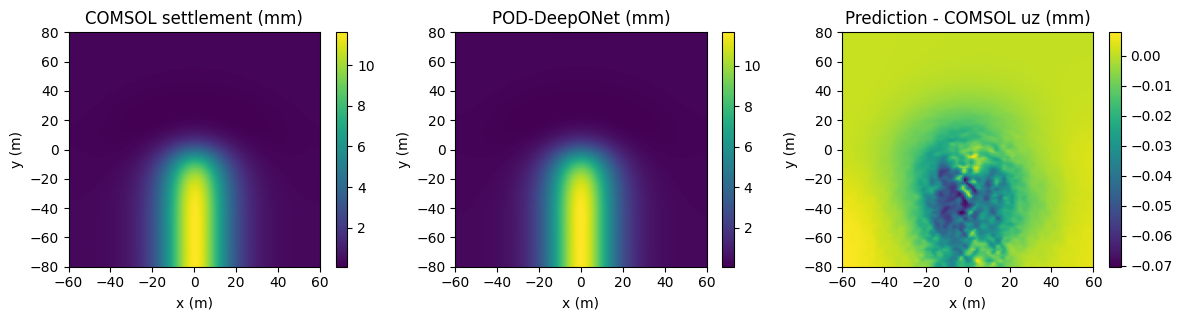

In [11]:
cid='MC005'; i=int(np.flatnonzero(manifest.case_id.eq(cid))[0]);sp,vp=predictions[cid]
ix=np.lexsort((SX[:,0],SX[:,1])); shape=(len(np.unique(SX[:,1])),len(np.unique(SX[:,0])))
fig,axes=plt.subplots(1,3,figsize=(12,3.3))
for ax,z,title in zip(axes,[-S[i],-sp,sp-S[i]],['COMSOL settlement (mm)','POD-DeepONet (mm)','Prediction - COMSOL uz (mm)']):
    im=ax.imshow(z[ix].reshape(shape),origin='lower',extent=[-60,60,-80,80],aspect='auto',cmap='viridis');fig.colorbar(im,ax=ax);ax.set(title=title,xlabel='x (m)',ylabel='y (m)')
fig.tight_layout();plt.show()
point_surface=pd.DataFrame(SX,columns=['x_m','y_m','z_m']);point_surface['COMSOL_uz_mm']=S[i];point_surface['predicted_uz_mm']=sp;point_surface['error_uz_mm']=sp-S[i]
point_surface.to_csv(OUT/f'{cid}_surface_pointwise.csv',index=False,encoding='utf-8-sig')
point_volume=pd.DataFrame(np.column_stack([VX,V[i,:,:3],vp[:,:3]]),columns=['x_m','y_m','z_m','true_ux_mm','true_uy_mm','true_uz_mm','pred_ux_mm','pred_uy_mm','pred_uz_mm'])
point_volume.to_csv(OUT/f'{cid}_volume_pointwise.csv',index=False,encoding='utf-8-sig')


### 新坐标查询与插值误差
原生坐标可直接解码；地表新坐标使用双线性插值，域内使用三维线性插值。查询不得落入洞内或超出有效网格范围。误差还包含插值误差。


In [12]:
query_xyz=np.array([[0.,-40.,-.001],[10.,-20.,-.001]])
query=op.query(H[i],query_xyz,kind='surface')
display(pd.DataFrame(np.column_stack([query_xyz,query]),columns=['x_m','y_m','z_m','uz_mm']))


,x_m,y_m,z_m,uz_mm
0,0.0,-40.0,-0.001,-11.608394
1,10.0,-20.0,-0.001,-6.927248


## 6. 冻结算子与稀疏沉降反演（手稿2.3、5.1）
主方案21个观测点由横向和纵向布点合并，取最近原生网格点并去重。地层类别已知，仅用于厚度上下界；正向网络不输入类别。每工况采用中心点+7个LHS初值，L-BFGS-B和自动微分。正则权重在18验证工况上从0、0.0001、0.001、0.01中选择，原选择为0。

下面保留原始种子、归一化、目标函数和求解容差。默认实际重算MC005；设RUN_ALL_INVERSION=True可重算18工况及验证权重选择。


In [13]:
config=json.loads((BASE/'results/inversion_计算前冻结方案.json').read_text('utf-8'))
inverse_freeze=json.loads((BASE/'results/inversion_测试前反演冻结.json').read_text('utf-8'))
centers=PROTOTYPES.copy(); lo=np.array(config['bounds_low_m']); hi=np.array(config['bounds_high_m'])
obs=pd.read_csv(BASE/'tables/inverse_观测坐标.csv')
ids={layout:g.native_index.to_numpy(int) for layout,g in obs.groupby('layout',sort=False)}
assert len(ids['joint'])==21
for layout,indices in ids.items():
    np.testing.assert_allclose(SX[indices],obs.query('layout==@layout')[['x_m','y_m','z_m']].to_numpy(),atol=1e-7)
branch=op.members[0]
for parameter in branch.parameters():parameter.requires_grad_(False)
end=int(offsets[1]); fs=fields[0]
dec={k:(torch.tensor(fs['mean'][ix]),torch.tensor(fs['basis'][:,ix])*float(fs['normalizer'])) for k,ix in ids.items()}
def response(h,layout):
    mean,basis=dec[layout]
    return -(mean+branch(h.reshape(1,3))[0,:end]@basis)
def invert_case(index,layout='joint',beta=0.,noise=0.,repeat=0):
    cid=manifest.iloc[index].case_id; family=ord(manifest.iloc[index].family)-65
    mid=(lo[family]+hi[family])/2; width=(hi[family]-lo[family])/2
    seed=config['seed']+int(cid[2:])*1009+repeat*7919
    clean=-S[index,ids[layout]]
    observed=clean+np.random.default_rng(seed).normal(0,noise,len(clean));target=torch.tensor(observed)
    starts=np.vstack([np.clip((centers[family]-mid)/width,-1,1),qmc.LatinHypercube(3,seed=seed+31).random(7)*1.9-.95])
    mt=torch.tensor(mid);wt=torch.tensor(width); candidates=[];trace=[];t0=time.perf_counter()
    def objective(z):
        q=torch.tensor(z,requires_grad=True);pred=response(mt+wt*q,layout)
        loss=((pred-target)**2).mean()+beta*(q*q).mean();gradient=torch.autograd.grad(loss,q)[0]
        trace.append(float(loss.detach()))
        return float(loss.detach()),gradient.detach().numpy()
    for k,z in enumerate(starts):
        result=minimize(objective,z,method='L-BFGS-B',jac=True,bounds=[(-1.,1.)]*3,options=dict(maxiter=200,ftol=1e-14,gtol=1e-9,maxls=40))
        thickness=mid+width*result.x
        candidates.append(dict(start=k,objective=float(result.fun),h31=thickness[0],h32=thickness[1],h33=thickness[2],success=bool(result.success),message=str(result.message)))
    best=min(candidates,key=lambda c:c['objective']);thickness=np.array([best[k] for k in ['h31','h32','h33']])
    pred=response(torch.tensor(thickness),layout).detach().numpy()
    return dict(case_id=cid,h=thickness,MAE_m=float(abs(thickness-H[index]).mean()),MAPE=float((abs(thickness-H[index])/H[index]).mean()),observed_RMSE_mm=float(np.sqrt(np.mean((pred-observed)**2))),clean_RMSE_mm=float(np.sqrt(np.mean((pred-clean)**2))),seconds=time.perf_counter()-t0,candidates=candidates,trace=trace)


,true_h_m,inferred_h_m,error_m
h31,14.484946,14.459881,-0.025065
h32,4.280227,4.231289,-0.048939
h33,3.644500,3.708115,0.063615


,start,objective,h31,h32,h33,success,message
0,0,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
1,1,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
2,2,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
3,3,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
4,4,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
5,5,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
6,6,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
7,7,0.000108,14.459881,4.231289,3.708115,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL


新运行MAE / MAPE: 0.04587310599631985 0.010206421423715927


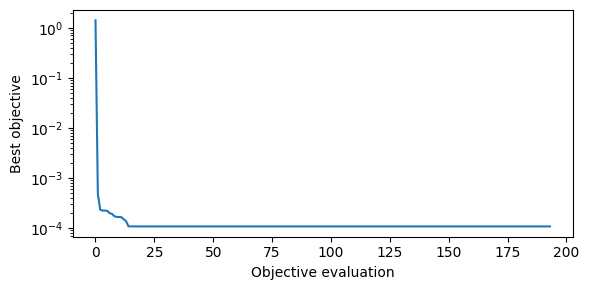

In [14]:
example=invert_case(i,beta=inverse_freeze['selected_beta'])
display(pd.DataFrame({'true_h_m':H[i],'inferred_h_m':example['h'],'error_m':example['h']-H[i]},index=['h31','h32','h33']))
display(pd.DataFrame(example['candidates']))
reference=pd.read_csv(BASE/'tables/inverse_主方案18工况.csv').set_index('case_id')
np.testing.assert_allclose(example['h'],reference.loc['MC005',['inferred_h1','inferred_h2','inferred_h3']].to_numpy(float),rtol=0,atol=0.003)
print('新运行MAE / MAPE:',example['MAE_m'],example['MAPE'])
plt.figure(figsize=(6,3));plt.semilogy(np.minimum.accumulate(example['trace']));plt.xlabel('Objective evaluation');plt.ylabel('Best objective');plt.tight_layout();plt.show()


In [15]:
if RUN_ALL_INVERSION:
    validation_scores=[]
    for beta in config['validation_betas']:
        results=[invert_case(j,beta=beta) for j in valid]
        validation_scores.append(dict(beta=beta,MAPE=np.mean([r['MAPE'] for r in results])))
    beta=min(validation_scores,key=lambda r:r['MAPE'])['beta']
    assert beta==inverse_freeze['selected_beta']
    new_inverse=[invert_case(j,beta=beta) for j in test]
    table=pd.DataFrame([{k:r[k] for k in ['case_id','MAE_m','MAPE','observed_RMSE_mm','seconds']} for r in new_inverse])
    table.to_csv(OUT/'inverse_18_recomputed.csv',index=False,encoding='utf-8-sig');display(table)
else:
    display(reference.reset_index()[['case_id','family','MAE_m','MAPE','observed_RMSE_mm','full_surface_RMSE_mm','full_volume_L2']])
print('论文记录层厚MAE:',reference.MAE_m.mean(),'m; MAPE:',reference.MAPE.mean()*100,'%')


,case_id,family,MAE_m,MAPE,observed_RMSE_mm,full_surface_RMSE_mm,full_volume_L2
0,MC005,A,0.045873,0.010206,0.010387,0.006971,0.018223
1,MC009,A,0.107583,0.020240,0.007696,0.006943,0.014259
2,MC015,A,0.142297,0.027040,0.010592,0.006191,0.015076
3,MC027,B,0.203144,0.030142,0.005797,0.013084,0.016853
4,MC033,B,0.084056,0.015373,0.006408,0.004745,0.014068
5,MC040,B,0.257861,0.047714,0.010292,0.016477,0.018143
6,MC042,C,0.046912,0.005372,0.009002,0.008556,0.014623
7,MC048,C,0.047703,0.005297,0.014239,0.010912,0.015317
8,MC054,C,0.082078,0.009921,0.025539,0.014470,0.019579
9,MC068,D,0.186653,0.021581,0.047977,0.029081,0.028169


论文记录层厚MAE: 0.138557066183044 m; MAPE: 2.0843732695016564 %


## 7. 噪声、全场重建与独立COMSOL复核（手稿5.2–5.4）
噪声标准差为0.05、0.10、0.20 mm，各重复3次，不同幅值共享标准正态噪声样本。默认读取完整记录，RUN_NOISE=True可重新求解。COMSOL复核表为已有三次独立有限元重算结果；本Notebook不启动COMSOL，也不将代理重建标记为有限元重算。


In [16]:
noise_summary=pd.read_csv(BASE/'tables/inverse_方案汇总.csv')
display(noise_summary)
if RUN_NOISE:
    noise_rows=[]
    for sigma in config['noise_sigma_mm']:
        for repeat in range(config['noise_repeats']):
            for j in test:
                r=invert_case(j,beta=inverse_freeze['selected_beta'],noise=sigma,repeat=repeat)
                noise_rows.append(dict(sigma_mm=sigma,repeat=repeat,case_id=r['case_id'],MAE_m=r['MAE_m'],MAPE=r['MAPE'],clean_RMSE_mm=r['clean_RMSE_mm']))
    pd.DataFrame(noise_rows).to_csv(OUT/'noise_recomputed.csv',index=False,encoding='utf-8-sig')
sp_inverse,vp_inverse=op.native(example['h'])
print('MC005反演后全地表RMSE (mm):',np.sqrt(np.mean((sp_inverse[0]-S[i])**2)))
print('MC005反演后域内位移相对L2:',np.linalg.norm(vp_inverse[0,:,:3]-V[i,:,:3])/np.linalg.norm(V[i,:,:3]))
display(pd.read_csv(BASE/'tables/inverse_独立COMSOL复核.csv'))


,scenario,MAE_m,MAPE,observed_RMSE_mm,clean_RMSE_mm,seconds
0,joint_clean,0.138557,0.020844,0.018735,0.018735,0.468563
1,joint_unpenalized,0.138557,0.020844,0.018735,0.018735,0.459347
2,noise_050,0.204364,0.030123,0.050094,0.026625,0.425378
3,noise_100,0.294793,0.042748,0.093729,0.038884,0.422650
4,noise_200,0.424869,0.061206,0.184865,0.064020,0.407429
5,transverse_clean,0.149931,0.021667,0.014330,0.014330,0.463193


MC005反演后全地表RMSE (mm): 0.006970800521597838
MC005反演后域内位移相对L2: 0.018223329610885065


,case_id,operator_observation_RMSE_mm,candidate_FE_observation_RMSE_mm,candidate_FE_vs_operator_RMSE_mm,candidate_FE_full_surface_RMSE_mm,operator_full_surface_RMSE_mm
0,MC005,0.010387,0.010898,0.011699,0.006101,0.006971
1,MC042,0.009002,0.018990,0.019548,0.013407,0.008556
2,MC115,0.017572,0.039333,0.031899,0.011832,0.007701


## 8. 手稿关键数值核对与适用范围
这些断言核对论文记录和新计算结果，不代表重新进行了训练或有限元求解。完整来源与SHA256见tables中的两个来源表。输入维度固定为三层厚度，材料和等效施工荷载固定；反演假定已知地层家族和厚度边界。


### 手稿一致性核查
手稿表3的逐工况峰值误差与来源记录一致，但均值写为0.062 mm；18条原始记录均值为0.0571978293 mm。交付表同时保留手稿原表和重新汇总值。加密点与辅助应力输出的口径差异也单独记录。


In [17]:
display(pd.read_csv(BASE/'tables/手稿与代码一致性核查.csv'))


,item,manuscript_value,code_or_source_value,unit,finding
0,Abstract surface RMSE,0.0197,0.019693,mm,与报告精度一致
1,Abstract volume RMSE,0.0622,0.062198,mm,与报告精度一致
2,Table 3 peak error mean,0.0620,0.057198,mm,手稿均值不同；逐工况值一致，按18行平均应约0.057
3,Table 3 volume RMSE mean,0.0620,0.062198,mm,与报告精度一致；勿与相邻峰值误差均值混淆
4,Section 3.3 training augmentation,1536.0000,0.000000,points/case,当前12.0 POD训练脚本使用固定网格；1536加密点属于旧A0流程
5,Section 4 training response groups,2.0000,3.000000,groups,原始训练损失含surface/displacement/stress；手稿重点讨论前两组


In [18]:
assert abs(metrics.surface_RMSE.mean()-0.019692550795291912)<1e-6
assert abs(metrics.volume_RMSE.mean()-0.06219819501693185)<1e-6
assert abs(reference.MAE_m.mean()-0.13855706618304403)<1e-10
assert abs(reference.MAPE.mean()-0.020843732695016617)<1e-10
assert digest(BASE/'models/最佳神经算子.pt')==freeze['checkpoint_sha256']
display(pd.read_csv(BASE/'tables/数据字典.csv'))
print('数据、权重、18工况正向预测及示例反演核对完成。')


,field,meaning,unit,definition
0,case_id,工况编号,无,120个独立数值模拟工况，不是空间点样本数
1,family,地层家族,A–F,每类20工况；正向部署只输入三层厚度，反演边界使用已知家族先验
2,split,冻结数据划分,train/validation/test,84/18/18；同一工况的全部空间点属于同一集合
3,h31_m / h32_m / h33_m,三层厚度,m,正向输入及反演未知量，分别对应③1、③2、③3
4,x_m / y_m / z_m,查询坐标,m,地表查询z=-0.001；固定原生查询网格，非有限元节点
5,ux_mm / uy_mm / uz_mm,位移分量,mm,保留COMSOL符号；沉降用于反演时采用-uz，正值向下
6,dsxx_kPa...dsyz_kPa,六分量应力增量,kPa,"按xx,yy,zz,xy,xz,yz顺序保留，为原代码辅助输出"
7,surface_relative_L2 / volume_relative_L2,相对L2误差,比例,机器表用0.0063；Excel显示为0.63%，不能再乘100
8,地表沉降相对L2 / 内部位移相对L2,手稿表3相对L2,百分数数值,18工况详细指标表.csv原始值0.4657代表0.4657%，区别于比例字段
9,MAPE,三层厚度平均绝对百分误差,比例,各层相对误差绝对值平均；Excel以百分比显示


数据、权重、18工况正向预测及示例反演核对完成。
